## [ICIT] Proposed

Code adapted from ([link](https://github.com/wanderfernandesjunior/mestrado))

n_jobs_tsfresh = 1
Pré-carregando instâncias anômalas...
    52 instâncias anômalas carregadas.
Rodada 1/52: well=WELL-00001, instância=WELL-00001_20140124213136
	ignorado porque normal_period_size é insuficiente (959)
Rodada 2/52: well=WELL-00002, instância=WELL-00002_20140126200050
	ignorado porque normal_period_size é insuficiente (1138)
Rodada 3/52: well=WELL-00006, instância=WELL-00006_20170801063614
Rodada 4/52: well=WELL-00006, instância=WELL-00006_20170802123000
Rodada 5/52: well=WELL-00006, instância=WELL-00006_20180618060245
Rodada 6/52: well=WELL-00002, instância=WELL-00002_20131104014101
Rodada 7/52: well=WELL-00003, instância=WELL-00003_20141122214325
Rodada 8/52: well=WELL-00003, instância=WELL-00003_20170728150240
Rodada 9/52: well=WELL-00003, instância=WELL-00003_20180206182917
	ignorado porque normal_period_size é insuficiente (586)
Rodada 10/52: well=WELL-00009, instância=WELL-00009_20170313160804
	ignorado porque não há amostras de treino suficientes
Rodada 11/52: we

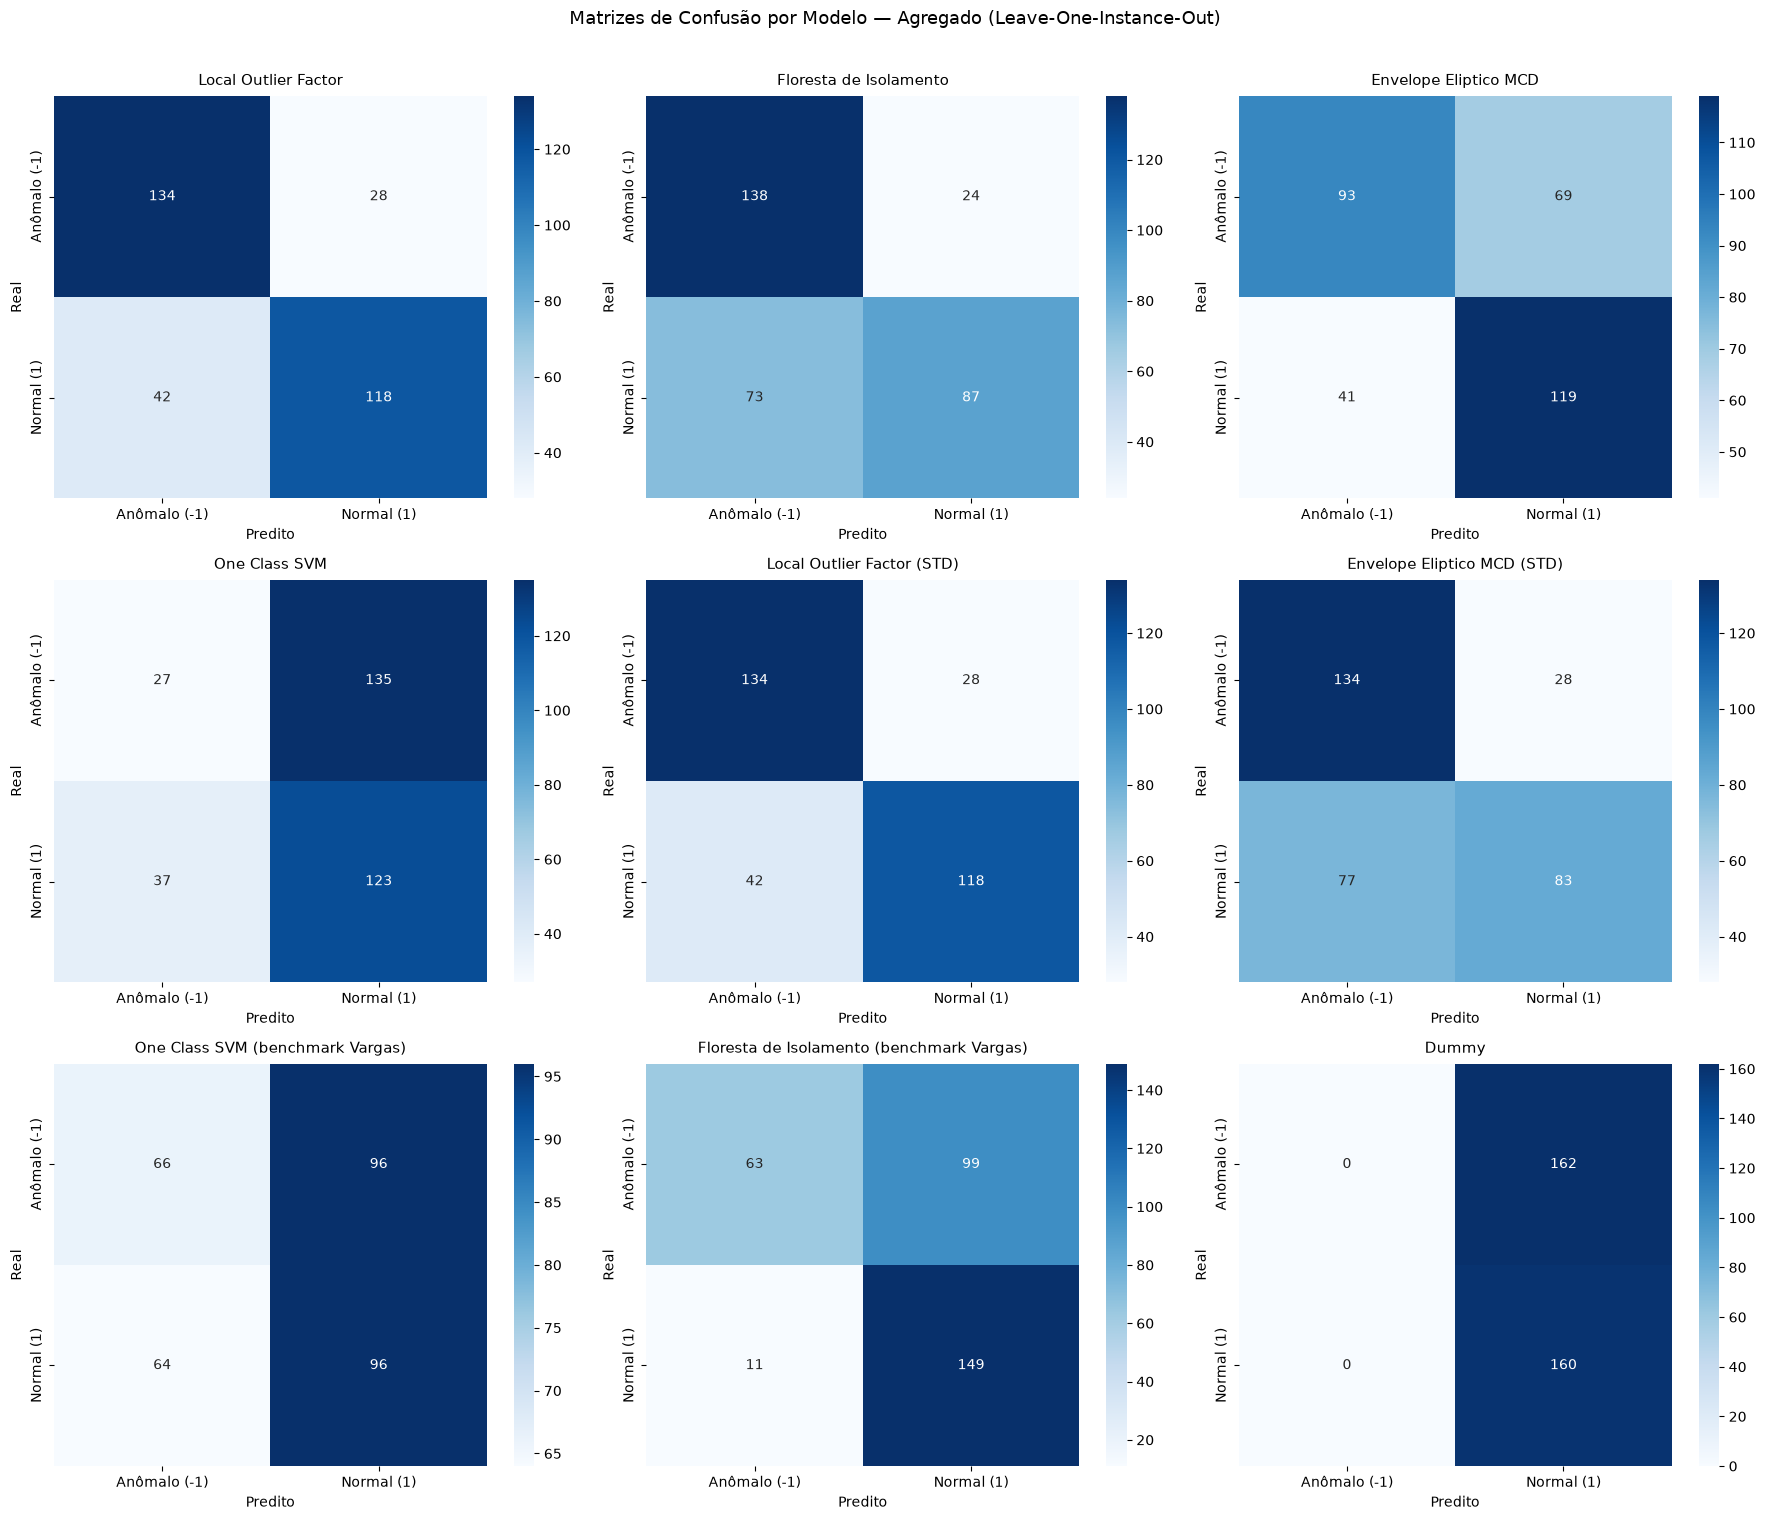

Tempo total de execução (hh:mm:ss.ms): 0:00:38.140396


In [2]:
from datetime import datetime
start_time = datetime.now()

import os
import sys
import pandas as pd
import numpy as np
import seaborn as sns
import logging
import warnings
from math import ceil
from matplotlib import pyplot as plt
from time import time
from pathlib import Path

from tsfresh.feature_extraction import extract_features
from tsfresh.utilities.dataframe_functions import impute
from tsfresh.feature_extraction import MinimalFCParameters

from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.dummy import DummyClassifier
from sklearn import preprocessing
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import confusion_matrix

logging.getLogger('tsfresh').setLevel(logging.ERROR)
warnings.simplefilter(action='ignore')

%matplotlib inline
%config InlineBackend.figure_format = 'png'

data_path = Path('./', 'data')

random_state = 1
np.random.seed(random_state)

n_jobs_tsfresh = 1
print(f'n_jobs_tsfresh = {n_jobs_tsfresh}')

events_names = {0: 'Normal', 1: 'Aumento Abrupto de BSW', 2: 'Fechamento Espúrio de DHSV',
                3: 'Intermitência Severa', 4: 'Instabilidade de Fluxo', 5: 'Perda Rápida de Produtividade',
                6: 'Restrição Rápida em CKP', 7: 'Incrustação em CKP', 8: 'Hidrato em Linha de Produção'}

vars = ['P-PDG', 'P-TPT', 'T-TPT', 'P-MON-CKP', 'T-JUS-CKP', 'P-JUS-CKGL', 'T-JUS-CKGL', 'QGL']
columns = ['timestamp'] + vars + ['class']

normal_class_code = 0
abnormal_classes_codes = [1, 2, 5, 6, 7, 8]

sample_size = 3 * 60
min_normal_period_size = 20 * 60
max_samples_per_period_test = 12

df_fc_p = MinimalFCParameters()
df_fc_p.pop('absolute_maximum')
df_fc_p.pop('sum_values')
df_fc_p.pop('length')

max_nan_percent = 0.1
std_vars_min = 0.01

clfs = {}
disable_progressbar = True


def class_and_file_generator(data_path, real=False, simulated=False, drawn=False):
    for class_path in data_path.iterdir():
        if class_path.is_dir():
            class_code = int(class_path.stem)
            for instance_path in class_path.iterdir():
                if instance_path.suffix == '.csv':
                    if (simulated and instance_path.stem.startswith('SIMULATED')) or \
                       (drawn and instance_path.stem.startswith('DRAWN')) or \
                       (real and not instance_path.stem.startswith('SIMULATED') and not instance_path.stem.startswith('DRAWN')):
                        yield class_code, instance_path


def load_instance(instance_path):
    try:
        well, instance_id = instance_path.stem.split('_')
        df = pd.read_csv(instance_path, sep=',', header=0)
        assert (df.columns == columns).all(), f'Colunas inválidas no arquivo {str(instance_path)}: {str(df.columns.tolist())}'
        return df
    except Exception as e:
        raise Exception(f'Erro ao ler arquivo {instance_path}: {e}')


def get_well(instance_path):
    return Path(instance_path).stem.split('_')[0]


def get_full_normal_period(df):
    mask = df['class'] == float(normal_class_code)
    return df.loc[mask].drop('class', axis=1).fillna(0)


def scale_samples_by_instance(df_samples, df_raw_instance, good_vars):
    sv = [v for v in good_vars if v in df_samples.columns]
    if not sv:
        return df_samples.copy(), None

    df_normal = get_full_normal_period(df_raw_instance)
    sv_available = [v for v in sv if v in df_normal.columns]
    if not sv_available:
        return df_samples.copy(), None

    scaler = preprocessing.StandardScaler()
    scaler.fit(df_normal[sv_available])

    df_scaled = df_samples.copy()
    df_scaled[sv_available] = scaler.transform(df_scaled[sv_available]).astype('float32')
    return df_scaled, scaler


def extract_normal_samples(df, n_samples_total, max_samples=None):
    ols = list(df['class'])
    df_vars = df.drop('class', axis=1)

    f_idx = ols.index(normal_class_code)
    l_idx = len(ols) - 1 - ols[::-1].index(normal_class_code)

    max_samples_normal = l_idx - f_idx + 1 - sample_size
    if max_samples_normal <= 0:
        return pd.DataFrame(), []

    max_non_overlapping = max_samples_normal // sample_size
    if max_non_overlapping <= 0:
        return pd.DataFrame(), []

    num_samples = min(n_samples_total, max_non_overlapping)
    if max_samples is not None:
        num_samples = min(num_samples, max_samples)
    if num_samples <= 0:
        return pd.DataFrame(), []

    step = sample_size
    frames = []
    y = []
    for idx in range(num_samples):
        f_idx_c = l_idx - sample_size + 1 - (num_samples - 1 - idx) * step
        l_idx_c = f_idx_c + sample_size
        df_sample = df_vars.iloc[f_idx_c:l_idx_c, :].copy()
        df_sample[vars] = df_sample[vars].fillna(0)
        df_sample.insert(loc=0, column='id', value=idx)
        frames.append(df_sample)
        y.append(normal_class_code)

    df_samples = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return df_samples, y


def extract_test_samples(df, class_code, num_test_samples):
    ols = list(df['class'])
    set_ols = set()
    for ol in ols:
        if ol in set_ols or np.isnan(ol):
            continue
        set_ols.add(int(ol))

    df_vars = df.drop('class', axis=1)
    transient_code = class_code + 100

    if transient_code in set_ols:
        f_idx_t = ols.index(transient_code)
        f_idx_t = max(f_idx_t - (sample_size - 1), 0)
        l_idx_t = len(ols) - 1 - ols[::-1].index(transient_code)
        max_transient_range = l_idx_t - f_idx_t + 1 - sample_size
        max_transient_samples = max_transient_range // sample_size
    else:
        max_transient_range = 0
        max_transient_samples = 0

    if class_code in set_ols:
        f_idx_r = ols.index(class_code)
        f_idx_r = max(f_idx_r - (sample_size - 1), 0)
        l_idx_r = len(ols) - 1 - ols[::-1].index(class_code)
        l_idx_r = min(l_idx_r + (sample_size - 1), len(ols) - 1)
        max_in_regime_range = l_idx_r - f_idx_r + 1 - sample_size
        max_in_regime_samples = max_in_regime_range // sample_size
    else:
        max_in_regime_range = 0
        max_in_regime_samples = 0

    num_transient_samples = ceil(num_test_samples / 2)
    num_in_regime_samples = num_test_samples - num_transient_samples

    if (max_transient_samples >= num_transient_samples) and (max_in_regime_samples < num_in_regime_samples):
        num_in_regime_samples = max_in_regime_samples
        num_transient_samples = min(num_test_samples - num_in_regime_samples, max_transient_samples)
    elif (max_transient_samples < num_transient_samples) and (max_in_regime_samples >= num_in_regime_samples):
        num_transient_samples = max_transient_samples
        num_in_regime_samples = min(num_test_samples - num_transient_samples, max_in_regime_samples)
    elif (max_transient_samples < num_transient_samples) and (max_in_regime_samples < num_in_regime_samples):
        num_transient_samples = max_transient_samples
        num_in_regime_samples = max_in_regime_samples

    frames = []
    y_test = []
    sample_id = 0

    if num_transient_samples > 0:
        step = sample_size
        for idx in range(num_transient_samples):
            f_idx_c = int(f_idx_t + idx * step)
            l_idx_c = f_idx_c + sample_size
            df_sample = df_vars.iloc[f_idx_c:l_idx_c, :].copy()
            df_sample[vars] = df_sample[vars].fillna(0)
            df_sample.insert(loc=0, column='id', value=sample_id)
            frames.append(df_sample)
            y_test.append(transient_code)
            sample_id += 1

    if num_in_regime_samples > 0:
        step = sample_size
        for idx in range(num_in_regime_samples):
            f_idx_c = int(f_idx_r + idx * step)
            l_idx_c = f_idx_c + sample_size
            df_sample = df_vars.iloc[f_idx_c:l_idx_c, :].copy()
            df_sample[vars] = df_sample[vars].fillna(0)
            df_sample.insert(loc=0, column='id', value=sample_id)
            frames.append(df_sample)
            y_test.append(class_code)
            sample_id += 1

    df_samples_test = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return df_samples_test, y_test


def train_test_calc_scores(X_train, y_train, X_test, y_test, scores, clfs, n_training_samples, n_test_samples, all_predictions, poco, instancia, classe):
    X_train.reset_index(inplace=True, drop=True)
    X_test.reset_index(inplace=True, drop=True)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    new_rows = []
    for clf_name, clf in clfs.items():
        t0 = time()
        clf.fit(X_train, y_train)
        t_train = time() - t0

        t0 = time()
        y_pred = clf.predict(X_test)
        t_test = time() - t0

        if clf_name not in all_predictions:
            all_predictions[clf_name] = {'y_true': [], 'y_pred': []}
        all_predictions[clf_name]['y_true'].extend(y_test.tolist())
        all_predictions[clf_name]['y_pred'].extend(y_pred.tolist())

        p = precision_score(y_test, y_pred, pos_label=1, average="micro")
        r = recall_score(y_test, y_pred, pos_label=1, average="micro")
        f1 = f1_score(y_test, y_pred, pos_label=1, average="micro")
        accuracy = accuracy_score(y_test, y_pred)

        new_rows.append({'POCO': poco, 'INSTANCIA': instancia, 'CLASSE': classe, 'CLASSIFICADOR': clf_name,
                          'PRECISAO': p, 'REVOGACAO': r, 'F1': f1, 'ACURACIA': accuracy,
                          'TREINAMENTO [s]': t_train, 'TESTE [s]': t_test,
                          'N_TRAINING_SAMPLES': n_training_samples, 'N_TEST_SAMPLES': n_test_samples})

    scores = pd.concat([scores, pd.DataFrame(new_rows)], ignore_index=True)
    return scores


# ---------------------------------------------------------------------------
# Carregamento das instâncias reais e anômalas
# (As instâncias da classe 0 NÃO são mais pré-carregadas nem usadas no treino)
# ---------------------------------------------------------------------------

real_instances = pd.DataFrame(class_and_file_generator(data_path, real=True, simulated=False, drawn=False),
                               columns=['class_code', 'instance_path'])
real_instances = real_instances.loc[real_instances.iloc[:, 0].isin(abnormal_classes_codes)].reset_index(drop=True)
real_instances['well'] = real_instances['instance_path'].apply(get_well)

print('Pré-carregando instâncias anômalas...')
instances_data = {}
for idx, row in real_instances.iterrows():
    try:
        instances_data[idx] = load_instance(row['instance_path'])
    except Exception as e:
        print(f'    Erro ao carregar instância {idx}: {e}')
        instances_data[idx] = None
print(f'    {len(instances_data)} instâncias anômalas carregadas.')

scores = pd.DataFrame()
all_predictions = {}
ignored_instances = 0
used_instances = 0

num_test_normal_samples_per_instance = max_samples_per_period_test // 2
num_test_abnormal_samples = max_samples_per_period_test - num_test_normal_samples_per_instance

for test_idx, test_row in real_instances.iterrows():
    test_class_code = test_row['class_code']
    test_instance_path = test_row['instance_path']
    test_well = test_row['well']
    test_instancia = Path(test_instance_path).stem
    test_classe = events_names.get(test_class_code, str(test_class_code))

    print(f'Rodada {test_idx + 1}/{len(real_instances)}: well={test_well}, instância={test_instancia}')

    df_test_instance = instances_data[test_idx]
    if df_test_instance is None:
        ignored_instances += 1
        print('\tignorado porque houve erro ao carregar a instância')
        continue

    normal_period_size = (df_test_instance['class'] == float(normal_class_code)).sum()
    if normal_period_size < min_normal_period_size:
        ignored_instances += 1
        print(f'\tignorado porque normal_period_size é insuficiente ({normal_period_size})')
        continue

    df_samples_test_normal, y_test_normal = extract_normal_samples(
        df_test_instance, num_test_normal_samples_per_instance, max_samples=max_samples_per_period_test)
    df_samples_test_abnormal, y_test_abnormal = extract_test_samples(
        df_test_instance, test_class_code, num_test_abnormal_samples)

    if df_samples_test_normal.empty and df_samples_test_abnormal.empty:
        ignored_instances += 1
        print('\tignorado porque não foi possível extrair amostras de teste')
        continue

    max_test_normal_id = df_samples_test_normal['id'].max() + 1 if not df_samples_test_normal.empty else 0
    if not df_samples_test_abnormal.empty:
        df_samples_test_abnormal = df_samples_test_abnormal.copy()
        df_samples_test_abnormal['id'] += max_test_normal_id

    df_samples_test = pd.concat([df_samples_test_normal, df_samples_test_abnormal], ignore_index=True)
    y_test = y_test_normal + y_test_abnormal

    same_well_mask = (real_instances['well'] == test_well)
    same_well_instances = real_instances[same_well_mask]

    train_frames_raw = []
    y_train = []
    global_sample_id = 0

    # Treino usa apenas os períodos normais extraídos de dentro das próprias
    # instâncias anômalas do mesmo poço (instâncias da classe 0 não são utilizadas).
    for train_idx, train_row in same_well_instances.iterrows():
        if train_idx == test_idx:
            continue
        df_train_instance = instances_data[train_idx]
        if df_train_instance is None:
            continue
        if (df_train_instance['class'] == float(normal_class_code)).sum() < min_normal_period_size:
            continue
        df_norm, y_norm = extract_normal_samples(df_train_instance, sys.maxsize, max_samples=None)
        if df_norm.empty:
            continue
        df_norm = df_norm.copy()
        df_norm['id'] += global_sample_id
        global_sample_id = df_norm['id'].max() + 1
        train_frames_raw.append((df_norm, df_train_instance))
        y_train.extend(y_norm)

    if not train_frames_raw:
        ignored_instances += 1
        print('\tignorado porque não há amostras de treino suficientes')
        continue

    df_samples_train_concat = pd.concat([f for f, _ in train_frames_raw], ignore_index=True)
    used_instances += 1

    y_train = np.array(y_train)
    y_test = np.array(y_test)

    y_train[y_train != normal_class_code] = -1
    y_train[y_train == normal_class_code] = 1
    y_test[y_test != normal_class_code] = -1
    y_test[y_test == normal_class_code] = 1

    good_vars = np.isnan(df_samples_train_concat[vars]).mean(0) <= max_nan_percent
    std_vars_arr = np.nanstd(df_samples_train_concat[vars], 0)
    good_vars &= (std_vars_arr > std_vars_min)
    good_vars = list(good_vars.index[good_vars])
    bad_vars = list(set(vars) - set(good_vars))

    scaled_train_frames = []
    global_sample_id = 0
    for df_norm, df_raw_inst in train_frames_raw:
        df_norm_clean = df_norm.drop(columns=bad_vars, errors='ignore').copy()
        df_norm_scaled, _ = scale_samples_by_instance(df_norm_clean, df_raw_inst, good_vars)
        df_norm_scaled['id'] = df_norm_scaled['id'] - df_norm_scaled['id'].min() + global_sample_id
        global_sample_id = df_norm_scaled['id'].max() + 1
        scaled_train_frames.append(df_norm_scaled)

    df_samples_train_scaled = pd.concat(scaled_train_frames, ignore_index=True)

    df_samples_test_clean = df_samples_test.drop(columns=bad_vars, errors='ignore').copy()
    df_samples_test_scaled, _ = scale_samples_by_instance(df_samples_test_clean, df_test_instance, good_vars)

    X_train = extract_features(df_samples_train_scaled, column_id='id', column_sort='timestamp',
                                default_fc_parameters=df_fc_p, impute_function=impute,
                                n_jobs=n_jobs_tsfresh, disable_progressbar=disable_progressbar)
    X_train = X_train.reset_index(drop=True)

    X_test = extract_features(df_samples_test_scaled, column_id='id', column_sort='timestamp',
                               default_fc_parameters=df_fc_p, impute_function=impute,
                               n_jobs=n_jobs_tsfresh, disable_progressbar=disable_progressbar)
    X_test = X_test.reset_index(drop=True)

    n_training_samples = len(X_train)
    n_test_samples = len(X_test)

    clfs = {
        'Local Outlier Factor': LocalOutlierFactor(n_neighbors=20, algorithm='auto', metric='euclidean', contamination='auto', novelty=True),
        'Floresta de Isolamento': IsolationForest(n_estimators=200, max_samples=0.75, contamination=0.1, max_features=1.0, bootstrap=False, random_state=1, verbose=0),
        'Envelope Eliptico MCD': EllipticEnvelope(contamination=0.001, assume_centered=False, support_fraction=0.99, random_state=1),
        'One Class SVM': OneClassSVM(kernel='sigmoid', gamma=0.01, nu=0.001),
        'Local Outlier Factor (STD)': LocalOutlierFactor(n_neighbors=20, algorithm='auto', metric='minkowski', contamination='auto', novelty=True),
        'Envelope Eliptico MCD (STD)': EllipticEnvelope(contamination=0.1, assume_centered=False, support_fraction=None, random_state=1),
        'One Class SVM (benchmark Vargas)': OneClassSVM(kernel='sigmoid', gamma='scale', nu=0.5),
        'Floresta de Isolamento (benchmark Vargas)': IsolationForest(n_jobs=None, contamination=0.000001, random_state=random_state),
        'Dummy': DummyClassifier(strategy='constant', constant=1)
    }

    scores = train_test_calc_scores(X_train, y_train, X_test, y_test, scores, clfs,
                                     n_training_samples, n_test_samples, all_predictions,
                                     poco=test_well, instancia=test_instancia, classe=test_classe)

print(f'Número de instâncias utilizadas: {used_instances}')
print(f'Número de instâncias ignoradas: {ignored_instances}')
print(f'Características utilizadas: {list(df_fc_p.keys())}')

scores.to_csv(r'./results/2-0_anomaly_detection_scores_reais_lowo.csv')

scores['RODADA'] = scores.groupby('CLASSIFICADOR').cumcount() + 1

metricas_desempenho = ['PRECISAO', 'REVOGACAO', 'F1', 'ACURACIA', 'TREINAMENTO [s]', 'TESTE [s]']
metricas_amostras = ['N_TRAINING_SAMPLES', 'N_TEST_SAMPLES']

sheet_names = {m: m.replace('[', '(').replace(']', ')').strip()[:31] for m in metricas_desempenho}

with pd.ExcelWriter(r'./results/2-0_anomaly_detection_scores_reais_lowo.xlsx', engine='openpyxl') as writer:
    for metrica in metricas_desempenho:
        pivot = scores.pivot_table(index=['POCO', 'INSTANCIA', 'CLASSE', 'RODADA'], columns='CLASSIFICADOR', values=metrica, aggfunc='first')
        pivot.columns.name = None
        pivot.to_excel(writer, sheet_name=sheet_names[metrica])

mean_score_table = (scores.groupby(['POCO', 'CLASSIFICADOR'])[metricas_desempenho].mean()
                     .sort_values(by=['POCO', 'F1'], ascending=[True, False]))
mean_score_table.to_csv(r'./results/2-0_anomaly_detection_scores_medias_reais_lowo.csv')
print(mean_score_table[['PRECISAO', 'REVOGACAO', 'F1', 'ACURACIA']])

std_score_table = (scores.groupby(['POCO', 'CLASSIFICADOR'])[metricas_desempenho].std()
                    .sort_values(by=['POCO', 'F1'], ascending=[True, True]))
std_score_table.to_csv(r'./results/2-0_anomaly_detection_scores_desvios_padrao_reais_lowo.csv')
print(std_score_table)

mean_score_table_geral = (scores.groupby('CLASSIFICADOR')[metricas_desempenho].mean()
                           .sort_values(by='F1', ascending=False))
mean_score_table_geral['N_RODADAS'] = scores.groupby('CLASSIFICADOR').size()
mean_score_table_geral.to_csv(r'./results/2-0_anomaly_detection_scores_medias_geral_lowo.csv')
print(mean_score_table_geral[['PRECISAO', 'REVOGACAO', 'F1', 'ACURACIA', 'N_RODADAS']])

std_score_table_geral = (scores.groupby('CLASSIFICADOR')[metricas_desempenho].std()
                          .sort_values(by='F1', ascending=True))
std_score_table_geral.to_csv(r'./results/2-0_anomaly_detection_scores_desvios_padrao_geral_lowo.csv')
print(std_score_table_geral)

amostras_por_rodada = (scores.drop_duplicates(subset=['POCO', 'INSTANCIA', 'RODADA'])
                        [['POCO', 'INSTANCIA', 'RODADA', 'N_TRAINING_SAMPLES', 'N_TEST_SAMPLES']])
amostras_resumo = amostras_por_rodada.groupby('POCO')[['N_TRAINING_SAMPLES', 'N_TEST_SAMPLES']].agg(['mean', 'std', 'min', 'max'])
amostras_resumo.to_csv(r'./results/2-0_anomaly_detection_n_amostras_por_poco_lowo.csv')
print(amostras_resumo)

labels = [-1, 1]
label_names = ['Anômalo (-1)', 'Normal (1)']

n_clfs = len(all_predictions)
n_cols = 3
n_rows = ceil(n_clfs / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes_flat = axes.flatten() if n_clfs > 1 else [axes]

for i, (clf_name, preds) in enumerate(all_predictions.items()):
    cm = confusion_matrix(preds['y_true'], preds['y_pred'], labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names, ax=axes_flat[i])
    axes_flat[i].set_title(clf_name, fontsize=11, pad=8)
    axes_flat[i].set_xlabel('Predito')
    axes_flat[i].set_ylabel('Real')

for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle('Matrizes de Confusão por Modelo — Agregado (Leave-One-Instance-Out)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(r'./results/2-0_confusion_matrices_lowo.png', bbox_inches='tight', dpi=150)
plt.show()

print(f'Tempo total de execução (hh:mm:ss.ms): {datetime.now() - start_time}')
